# Solution: Mission 01 — Taxi Analytics dbt Project

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import contextlib
import io
import json
import shutil
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

WORK = Path(tempfile.mkdtemp())

import os

os.environ["DBT_USE_COLORS"] = "false"
from dbt.cli.main import dbtRunner

PROJ = WORK / "mobility"
for sub in ["models/staging", "models/marts", "seeds", "tests"]:
    (PROJ / sub).mkdir(parents=True, exist_ok=True)

def put(rel, text):
    (PROJ / rel).write_text(text.strip() + "\n", encoding="utf-8")

def dbt(*args):
    res = dbtRunner().invoke([*args, "--project-dir", str(PROJ), "--profiles-dir", str(PROJ), "--quiet"])
    return res.success, (list(res.result) if res.result is not None and hasattr(res.result, "__iter__") else [])

## Task 1: Project, Source, Seed

In [2]:
put("dbt_project.yml", """
name: mobility
version: "1.0"
profile: mobility
models:
  mobility:
    staging: {+materialized: view}
    marts: {+materialized: table}
""")
put("profiles.yml", f"""
mobility:
  target: dev
  outputs:
    dev: {{type: duckdb, path: "{WORK / 'mobility.duckdb'}", threads: 4}}
""")
files = [str(datasets.taxi(m)) for m in ["2024-01", "2024-02"]]
put("models/staging/sources.yml", f"""
version: 2
sources:
  - name: tlc
    tables:
      - name: yellow_trips
        meta: {{external_location: "read_parquet({files})"}}
""")
_ = shutil.copy(datasets.fetch("taxi_zone_lookup.csv"), PROJ / "seeds" / "taxi_zones.csv")

## Tasks 2–3: Staging and Marts

In [3]:
put("models/staging/stg_trips.sql", """
-- cleaning rules: pickup in Jan-Feb 2024, fare $3-$500, distance 0.1-100 mi, duration 1-180 min
select tpep_pickup_datetime as pickup_at, cast(PULocationID as integer) as pickup_zone_id,
       total_amount, fare_amount, tip_amount, payment_type
from {{ source('tlc', 'yellow_trips') }}
where tpep_pickup_datetime >= '2024-01-01' and tpep_pickup_datetime < '2024-03-01'
  and fare_amount between 3 and 500 and trip_distance between 0.1 and 100
  and date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) between 60 and 10800
""")
put("models/staging/stg_zones.sql", """
select cast(LocationID as integer) as zone_id, Borough as borough, Zone as zone from {{ ref('taxi_zones') }}
""")
put("models/marts/dim_zones.sql", """
select zone_id, borough, zone, zone_id in (1, 132, 138) as is_airport from {{ ref('stg_zones') }}
""")
put("models/marts/fct_daily_zone.sql", """
{{ config(materialized='incremental', unique_key=['day', 'zone_id'], incremental_strategy='delete+insert') }}
-- grain: one row per day and pickup zone
select cast(pickup_at as date) as day, pickup_zone_id as zone_id, count(*) as trips, round(sum(total_amount), 2) as revenue
from {{ ref('stg_trips') }}
{% if is_incremental() %}
where cast(pickup_at as date) >= (select max(day) - interval 2 day from {{ this }})     -- 2-day lookback for late data
{% else %}
where pickup_at < '{{ var("first_load_until", "2024-03-01") }}'
{% endif %}
group by all
""")
put("models/marts/mart_hourly_demand.sql", """
-- grain: one row per borough, weekday and hour (average trips per hour)
with hourly as (
    select date_trunc('hour', t.pickup_at) as hour, z.borough, count(*) as trips
    from {{ ref('stg_trips') }} t join {{ ref('dim_zones') }} z on z.zone_id = t.pickup_zone_id
    group by all
)
select borough, isodow(hour) as weekday, hour(hour) as hour_of_day, round(avg(trips), 1) as avg_trips
from hourly group by all
""")

## Task 4: Tests

In [4]:
put("models/marts/schema.yml", """
version: 2
models:
  - name: dim_zones
    columns:
      - name: zone_id
        data_tests: [unique, not_null]
  - name: fct_daily_zone
    columns:
      - name: zone_id
        data_tests:
          - relationships: {arguments: {to: ref('dim_zones'), field: zone_id}}
      - name: trips
        data_tests: [not_null]
  - name: mart_hourly_demand
    columns:
      - name: hour_of_day
        data_tests:
          - accepted_values: {arguments: {values: [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]}}
""")
put("tests/fct_daily_zone_grain.sql", """
select day, zone_id from {{ ref('fct_daily_zone') }} group by day, zone_id having count(*) > 1
""")
put("tests/fct_daily_zone_reconciles.sql", """
-- compare only the days already loaded into the (incremental) fact table
select abs((select sum(revenue) from {{ ref('fct_daily_zone') }})
         - (select sum(total_amount) from {{ ref('stg_trips') }}
            where cast(pickup_at as date) in (select day from {{ ref('fct_daily_zone') }}))) as diff
having diff > 1
""")

## Task 5: Incremental Run

The first build loads data until 2024-02-20 (as if the rest had not arrived yet); the second run picks up the remaining days, with the 2-day lookback, and the reconciliation test confirms that nothing was duplicated.

In [5]:
ok1, res1 = dbt("build", "--vars", "{first_load_until: '2024-02-20'}")
con = duckdb.connect(str(WORK / "mobility.duckdb"))
d1 = con.sql("select count(*), max(day) from main.fct_daily_zone").fetchone()
con.close()
ok2, res2 = dbt("build", "--select", "fct_daily_zone+")
con = duckdb.connect(str(WORK / "mobility.duckdb"))
d2 = con.sql("select count(*), max(day) from main.fct_daily_zone").fetchone()
con.close()
ok3, res3 = dbt("build", "--select", "fct_daily_zone+")          # idempotent re-run
con = duckdb.connect(str(WORK / "mobility.duckdb"))
d3 = con.sql("select count(*), max(day) from main.fct_daily_zone").fetchone()
con.close()
print(f"first build ok={ok1}: {d1[0]:,} rows up to {d1[1]}")
print(f"incremental  ok={ok2}: {d2[0]:,} rows up to {d2[1]}")
print(f"re-run       ok={ok3}: {d3[0]:,} rows up to {d3[1]} (unchanged: {d2 == d3})")

first build ok=True: 10,938 rows up to 2024-02-19
incremental  ok=True: 13,178 rows up to 2024-02-29
re-run       ok=True: 13,178 rows up to 2024-02-29 (unchanged: True)


## Task 6: Report

 type  status  nodes
model success      5
 seed success      1
 test    pass      7


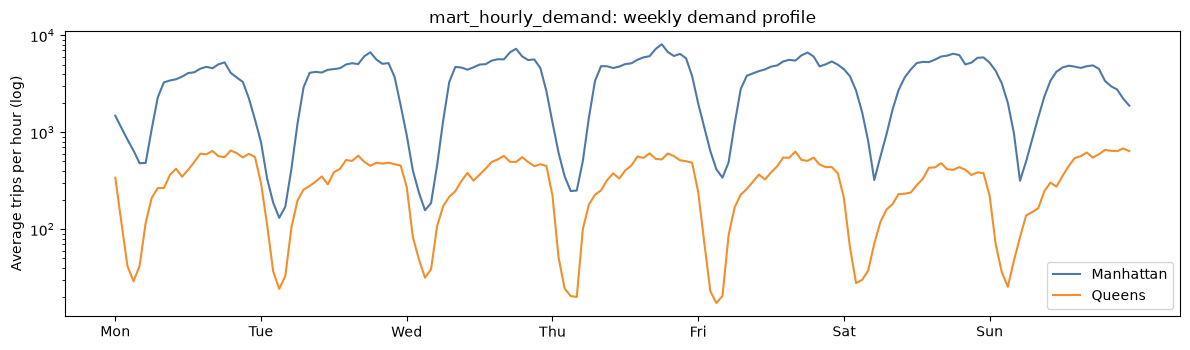

fct_daily_zone       <- ['stg_trips']
mart_hourly_demand   <- ['stg_trips', 'dim_zones']
dim_zones            <- ['stg_zones']
stg_zones            <- ['taxi_zones']
stg_trips            <- ['yellow_trips']


In [6]:
summary = pd.DataFrame([{"node": r.node.name, "type": str(r.node.resource_type).split(".")[-1], "status": str(r.status).split(".")[-1]}
                        for r in res1])
print(summary.groupby(["type", "status"]).size().rename("nodes").reset_index().to_string(index=False))

con = duckdb.connect(str(WORK / "mobility.duckdb"))
prof = con.sql("select * from main.mart_hourly_demand where borough in ('Manhattan', 'Queens')").df()
con.close()
prof["hour_of_week"] = (prof["weekday"] - 1) * 24 + prof["hour_of_day"]
fig, ax = plt.subplots(figsize=(12, 3.6))
for b, c in [("Manhattan", "#4E79A7"), ("Queens", "#F28E2B")]:
    part = prof[prof["borough"] == b].sort_values("hour_of_week")
    ax.plot(part["hour_of_week"], part["avg_trips"], color=c, label=b)
ax.set(xticks=range(0, 168, 24), xticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], yscale="log",
       ylabel="Average trips per hour (log)", title="mart_hourly_demand: weekly demand profile")
ax.legend()
plt.tight_layout()
plt.show()

manifest = json.loads((PROJ / "target" / "manifest.json").read_text())
for uid, n in manifest["nodes"].items():
    if n["resource_type"] == "model":
        print(f"{n['name']:<20} <- {[d.split('.')[-1] for d in n['depends_on']['nodes']]}")